# 4. Scraping de Wikipedia — cultura de Miami (+ automatización con Selenium)

Este avance usa **inteligencia artificial** para generar el script de scraping: el código de este notebook fue generado con **Claude (Anthropic)** a partir de las consignas, y luego revisado y ejecutado como parte del proyecto.

Consta de dos partes:

1. **Scraping de la cultura de Miami** (la ciudad elegida en `1_EDA.ipynb`): se extrae la sección *Cultura* de su artículo de Wikipedia en español con `requests` + `BeautifulSoup`, y se guarda como dataset.
2. **Pasos extra con Selenium**: se automatiza un navegador real (Microsoft Edge en modo headless) para entrar al artículo de Miami, buscar otra de las ciudades disponibles en el buscador interno (**Chicago**), cambiar el color del sitio a **Oscuro** y cambiar el **idioma** de la página a inglés. Cada paso queda verificado por código y documentado con una captura de pantalla.

Pautas respetadas: user-agent identificable, una sola petición por página y uso de un sitio que permite el acceso automatizado a sus artículos.

## 4.1 Scraping de la sección "Cultura" del artículo de Miami

El artículo `es.wikipedia.org/wiki/Miami` organiza su contenido en secciones (`<section>`), cada una con su encabezado. Se localiza el encabezado `Cultura` y se recorren sus subsecciones (`h3`) extrayendo los párrafos, limpiando las marcas de referencia (`[1]`, `[2]`, …).

In [1]:
import re
import requests
import pandas as pd
from bs4 import BeautifulSoup

URL_MIAMI = "https://es.wikipedia.org/wiki/Miami"
UA = {"User-Agent": "ProyectoM1-educativo/1.0 (curso de Data Science)"}

respuesta = requests.get(URL_MIAMI, headers=UA, timeout=20)
print("Status:", respuesta.status_code)
soup = BeautifulSoup(respuesta.text, "html.parser")
print("Artículo:", soup.find("h1").get_text(strip=True))

def limpiar(texto):
    """Quita las marcas de referencia [n] y espacios raros del texto de Wikipedia."""
    return re.sub(r"\[\d+\]\u200b?", "", texto).strip()

# La sección Cultura: su encabezado h2 vive en un div, dentro del <section> que contiene todo
seccion_cultura = soup.find("h2", id="Cultura").find_parent("section")

filas = []
for sub in seccion_cultura.find_all("section", recursive=False):
    titulo = sub.find(["h3", "h4"]).get_text(strip=True)
    for p in sub.find_all("p", recursive=False):
        texto = limpiar(p.get_text(" ", strip=True))
        if len(texto) > 40:
            filas.append({"subseccion": titulo, "parrafo": texto})

cultura = pd.DataFrame(filas)
print("\nPárrafos extraídos:", len(cultura))
print(cultura["subseccion"].value_counts().to_string())

Status: 200


Artículo: Miami

Párrafos extraídos: 14
subseccion
Música popular                        6
Entretenimientos y artes escénicas    5
Medios de comunicación                3


In [2]:
# Muestra del contenido extraído: el primer párrafo de cada subsección
for sub in cultura["subseccion"].unique():
    primero = cultura.loc[cultura["subseccion"] == sub, "parrafo"].iloc[0]
    print(f"=== {sub} ===")
    print(primero[:400], "...\n")

=== Entretenimientos y artes escénicas ===
Miami cuenta con importantes atracciones culturales como teatros , museos , parques y centros de artes escénicas . La adición más reciente es el Adrianne Arsht Center of the Performing Arts inaugurado en octubre de 2006 con el nombre de Carnival Center, es el segundo centro de artes más grande en Estados Unidos después del Lincoln Center en Nueva York y es la sede de la Gran Ópera de Florida . Cul ...

=== Música popular ===
La música popular en Miami es variada. Los cubanos trajeron la salsa , la conga y la rumba de sus tierras natales y de inmediato la popularizaron en la cultura americana . Los puertorriqueños y panameños trajeron consigo un nuevo ritmo musical, el reguetón . Los dominicanos hicieron lo mismo con la bachata y el merengue , mientras que los colombianos trajeron el vallenato y la cumbia colombiana ;  ...

=== Medios de comunicación ===
Son varios los periódicos que se editan en Miami, entre los que destacan The Miami Herald ,

In [3]:
# Guardar el dataset de cultura para el repositorio
RUTA_CULTURA = "../../Datasets/cultura_miami.csv"
cultura.to_csv(RUTA_CULTURA, index=False, encoding="utf-8")
print("Guardado:", RUTA_CULTURA, "—", len(cultura), "párrafos de", cultura["subseccion"].nunique(), "subsecciones")

Guardado: ../../Datasets/cultura_miami.csv — 14 párrafos de 3 subsecciones


## 4.2 Pasos extra — automatización con Selenium

Flujo pedido por la consigna, automatizado sobre **Microsoft Edge headless** (Selenium 4 descarga el driver automáticamente):

1. Acceder a la página de Wikipedia de la ciudad elegida (**Miami**).
2. Buscar en el **buscador interno** otra de las ciudades disponibles en la base (**Chicago**).
3. En la página de Chicago, cambiar el color del sitio a **"Oscuro"** (el default de Wikipedia es claro). Se verifica por la clase `skin-theme-clientpref-night` del HTML.
4. Cambiar el **idioma** del artículo a **inglés** (distinto del español default). Se verifica por la URL (`en.wikipedia.org`) y el atributo `lang` del HTML.

Cada paso guarda una captura en `capturas/`. Dos detalles técnicos que descubrimos al automatizar: el buscador de Wikipedia **reemplaza el campo de texto por un componente dinámico** al recibir el foco (hay que re-localizar el elemento para no usar una referencia obsoleta), y la preferencia de color se guarda **por dominio**, por lo que al saltar a `en.wikipedia.org` la página vuelve al tema claro.

In [4]:
import os
import time
from selenium import webdriver
from selenium.webdriver.common.by import By
from selenium.webdriver.common.keys import Keys
from selenium.webdriver.edge.options import Options
from selenium.webdriver.support.ui import WebDriverWait
from selenium.webdriver.support import expected_conditions as EC

os.makedirs("capturas", exist_ok=True)

opciones = Options()
opciones.add_argument("--headless=new")        # sin ventana: apto para ejecutar desde el notebook
opciones.add_argument("--window-size=1600,1000")
driver = webdriver.Edge(options=opciones)
espera = WebDriverWait(driver, 15)

# --- Paso 1: página de Wikipedia de la ciudad elegida (Miami) ---
driver.get("https://es.wikipedia.org/wiki/Miami")
espera.until(EC.presence_of_element_located((By.ID, "firstHeading")))
print("Paso 1 —", driver.find_element(By.ID, "firstHeading").text, "|", driver.current_url)
driver.save_screenshot("capturas/1_miami.png")

Paso 1 — Miami | https://es.wikipedia.org/wiki/Miami


True

In [5]:
# --- Paso 2: búsqueda interna de otra ciudad de la base (Chicago) ---
caja = espera.until(EC.element_to_be_clickable((By.NAME, "search")))
caja.click()
time.sleep(1)                                    # Wikipedia reemplaza el input al enfocarlo...
caja = driver.find_element(By.NAME, "search")    # ...así que se re-localiza la referencia
caja.send_keys("Chicago" + Keys.ENTER)
espera.until(EC.url_contains("Chicago"))
espera.until(EC.presence_of_element_located((By.ID, "firstHeading")))
print("Paso 2 —", driver.find_element(By.ID, "firstHeading").text, "|", driver.current_url)
driver.save_screenshot("capturas/2_busqueda_chicago.png")

Paso 2 — Chicago | https://es.wikipedia.org/wiki/Chicago


True

In [6]:
# --- Paso 3: cambiar el color del sitio a "Oscuro" ---
radio_oscuro = driver.find_elements(By.ID, "skin-client-pref-skin-theme-value-night")
if not radio_oscuro or not radio_oscuro[0].is_displayed():
    # en pantallas angostas el panel Apariencia se colapsa en un menú: se abre primero
    boton = driver.find_element(By.CSS_SELECTOR, "#vector-appearance-dropdown > label, #vector-appearance-dropdown input")
    driver.execute_script("arguments[0].click();", boton)
    time.sleep(1)
    radio_oscuro = driver.find_elements(By.ID, "skin-client-pref-skin-theme-value-night")
driver.execute_script("arguments[0].click();", radio_oscuro[0])
time.sleep(1)

clases_html = driver.find_element(By.TAG_NAME, "html").get_attribute("class")
assert "skin-theme-clientpref-night" in clases_html, "el tema oscuro no se aplicó"
print("Paso 3 — tema del sitio: OSCURO (clase skin-theme-clientpref-night verificada)")
driver.save_screenshot("capturas/3_tema_oscuro.png")

Paso 3 — tema del sitio: OSCURO (clase skin-theme-clientpref-night verificada)


True

In [7]:
# --- Paso 4: cambiar el idioma del artículo (español -> inglés) ---
boton_idiomas = espera.until(EC.element_to_be_clickable((By.CSS_SELECTOR, "#p-lang-btn button, #p-lang-btn label")))
driver.execute_script("arguments[0].click();", boton_idiomas)
time.sleep(2)

enlace_en = driver.find_element(By.CSS_SELECTOR, "a[lang='en']")   # enlace interwiki al artículo en inglés
driver.execute_script("arguments[0].click();", enlace_en)
espera.until(EC.url_contains("en.wikipedia.org"))
espera.until(EC.presence_of_element_located((By.ID, "firstHeading")))

print("Paso 4 —", driver.find_element(By.ID, "firstHeading").text, "|", driver.current_url)
print("         idioma del documento:", driver.find_element(By.TAG_NAME, "html").get_attribute("lang"))
driver.save_screenshot("capturas/4_idioma_ingles.png")

driver.quit()
print("\nFlujo Selenium completado: 4 pasos verificados, capturas guardadas en capturas/")

Paso 4 — Chicago | https://en.wikipedia.org/wiki/Chicago
         idioma del documento: en



Flujo Selenium completado: 4 pasos verificados, capturas guardadas en capturas/


### Evidencia: capturas de cada paso

Paso 1 — Artículo de Miami (es.wikipedia.org)


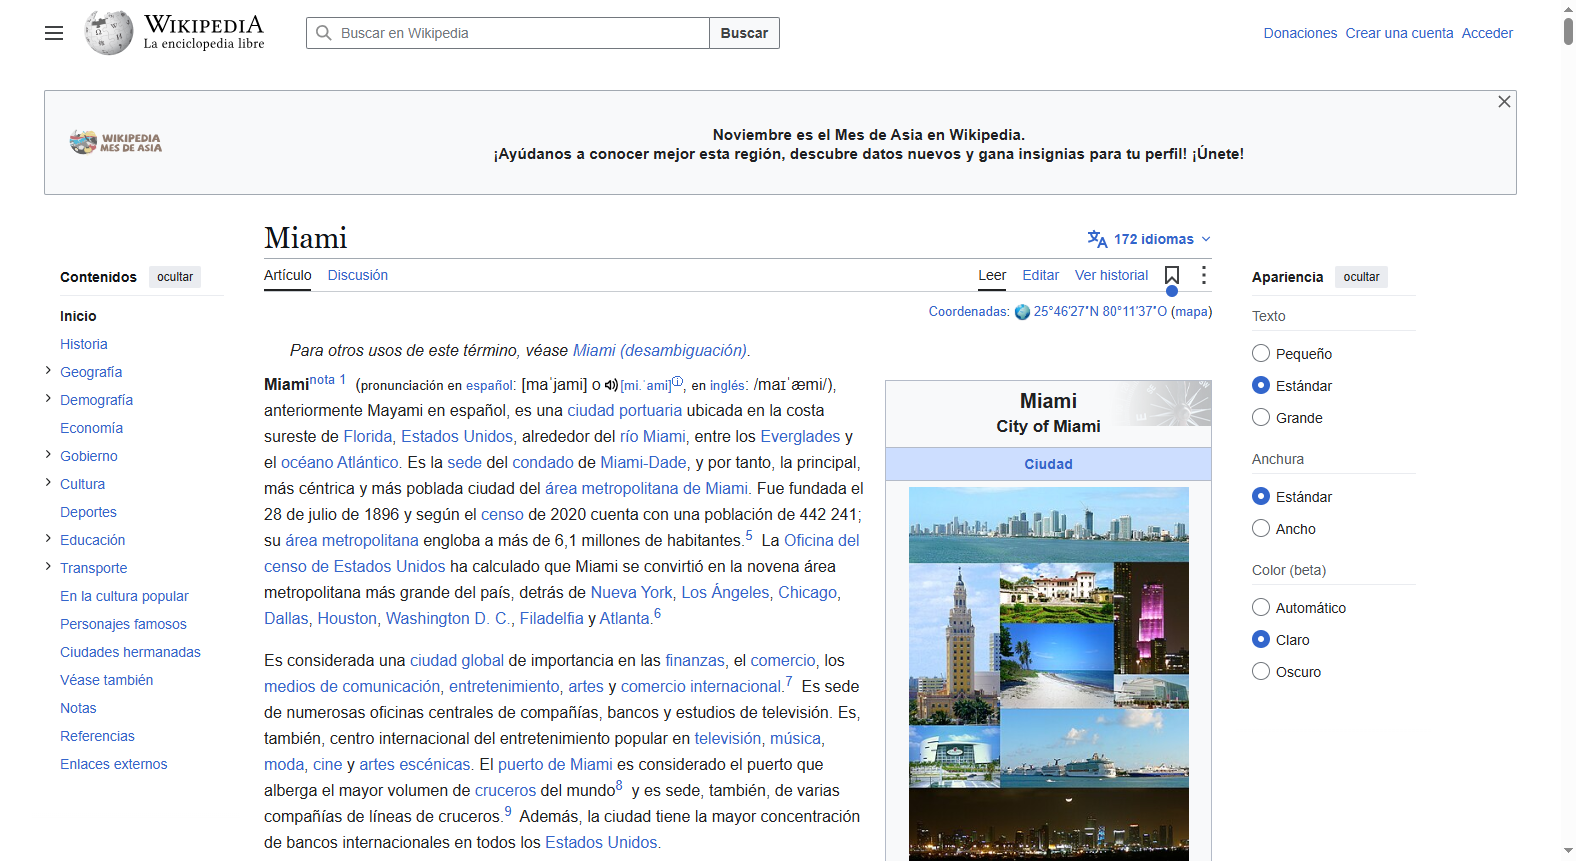

Paso 2 — Chicago, encontrado con el buscador interno


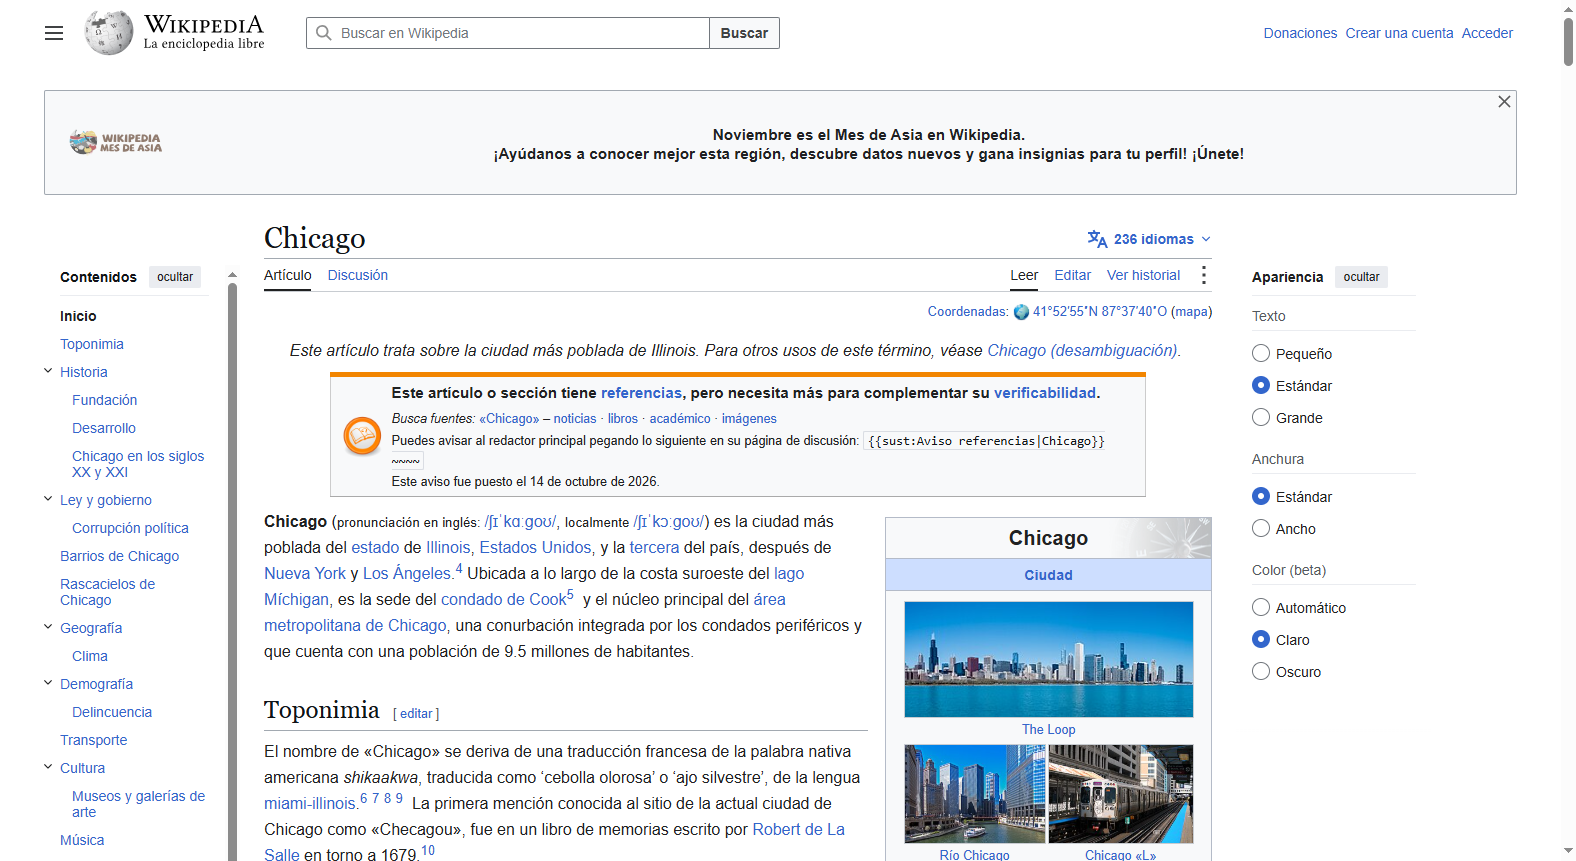

Paso 3 — Color del sitio cambiado a Oscuro


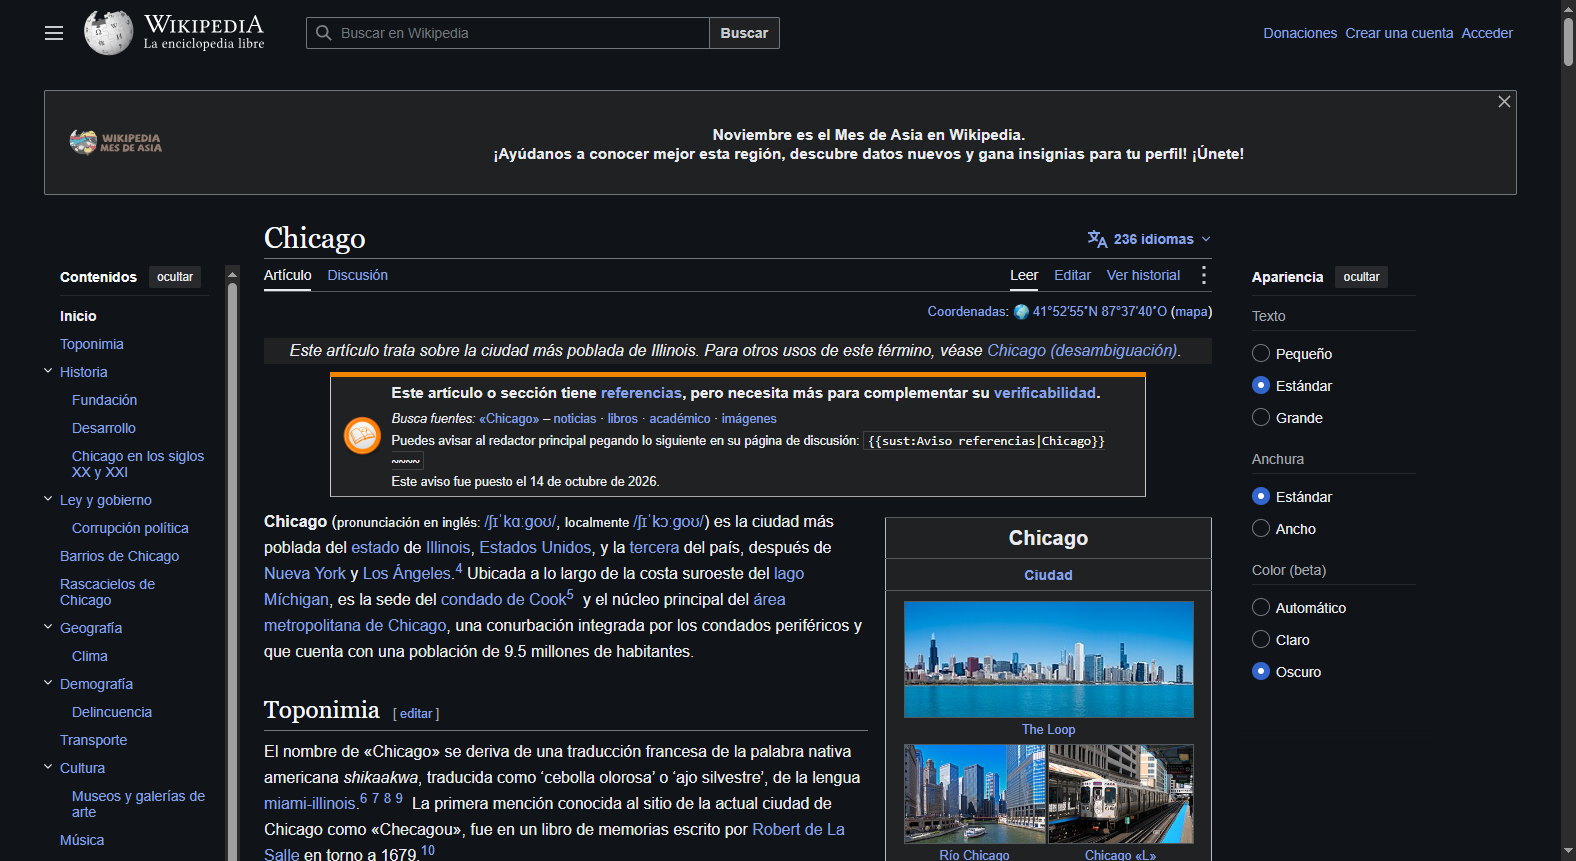

Paso 4 — Idioma cambiado a inglés (en.wikipedia.org)


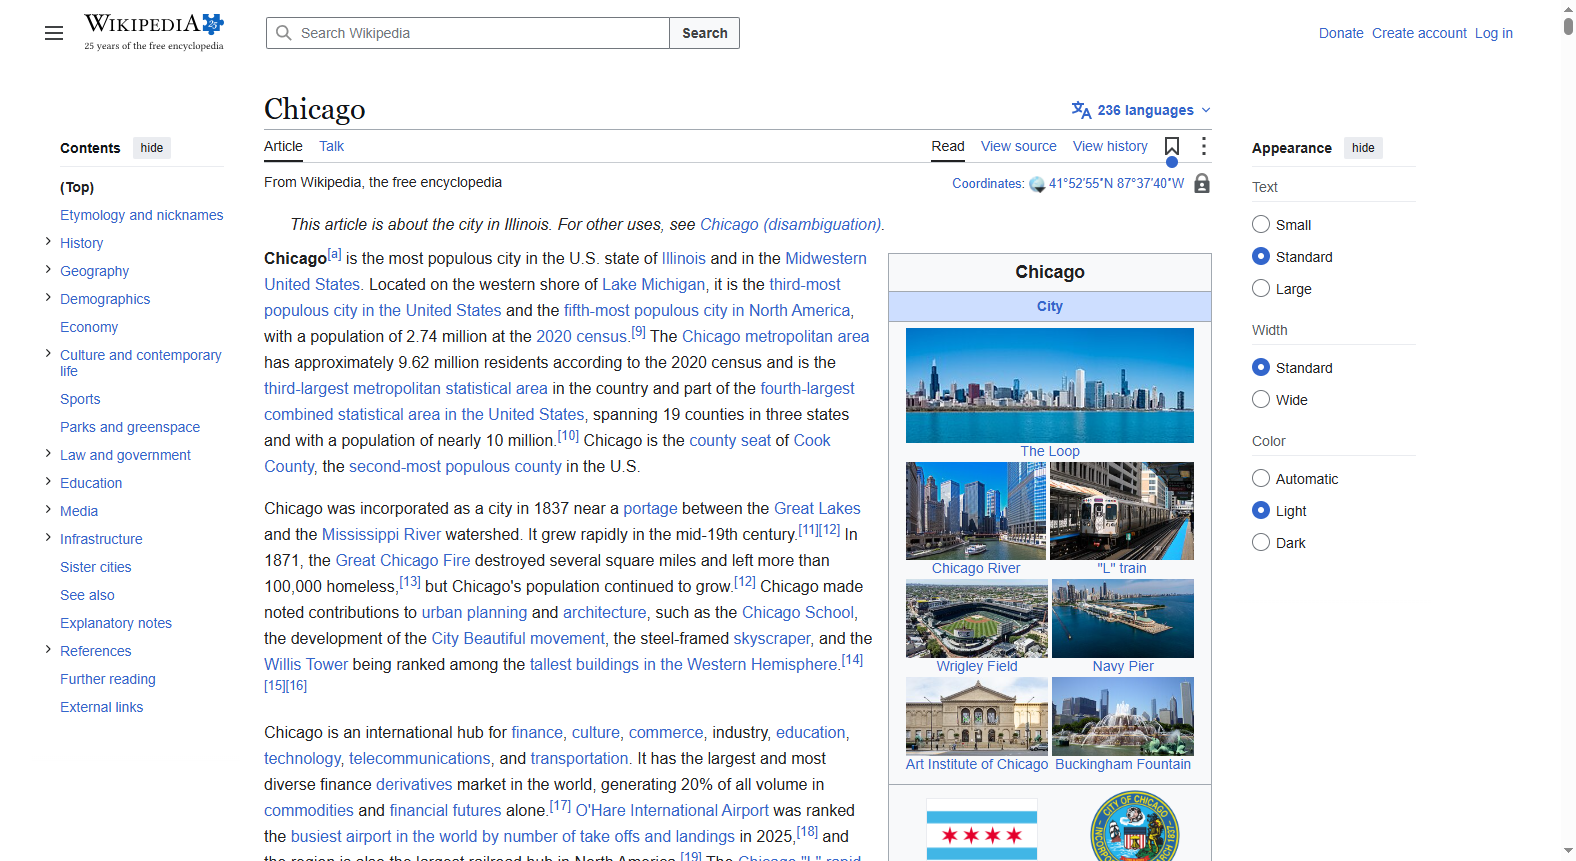

In [8]:
from IPython.display import Image, display

for archivo, titulo in [
    ("capturas/1_miami.png", "Paso 1 — Artículo de Miami (es.wikipedia.org)"),
    ("capturas/2_busqueda_chicago.png", "Paso 2 — Chicago, encontrado con el buscador interno"),
    ("capturas/3_tema_oscuro.png", "Paso 3 — Color del sitio cambiado a Oscuro"),
    ("capturas/4_idioma_ingles.png", "Paso 4 — Idioma cambiado a inglés (en.wikipedia.org)"),
]:
    print(titulo)
    display(Image(filename=archivo, width=950))

## Conclusiones

- Se extrajo la sección **Cultura** del artículo de Miami en Wikipedia (subsecciones de entretenimiento/artes escénicas, música popular y medios de comunicación) y se guardó en `Datasets/cultura_miami.csv`. El contenido confirma el perfil que venimos viendo en los datos: Miami como polo cultural y gastronómico, con fuerte identidad latina — coherente con que sea la ciudad de mayor gasto en restaurantes de la base.
- Los **pasos extra con Selenium** se completaron y verificaron programáticamente: navegación al artículo de Miami → búsqueda interna de Chicago → color del sitio en **Oscuro** (verificado por la clase del HTML) → idioma cambiado a **inglés** (verificado por URL y atributo `lang`).
- El script fue **generado con IA (Claude)**, como pide la consigna, y la automatización dejó dos aprendizajes técnicos documentados: manejar referencias obsoletas cuando la página reemplaza elementos dinámicamente, y que las preferencias de apariencia de Wikipedia son por dominio/idioma.